# 01 · Explore & base-filter MultiCaRe for Emergency Medicine

**Goal:** see what classes and parameters MultiCaRe offers, then apply a first *base filter* for emergency-medicine cases so the group can review candidates by hand.

**Data** (CC BY 4.0, per-image article licences vary):
- `OpenMed/multicare-cases` – one row per article, each holding 1+ patient cases (`case_id`, `age`, `gender`, `case_text`)
- `OpenMed/multicare-images` – one row per (sub)image with `caption`, labels and `patient_id`
- Join key: `cases.case_id` = `images.patient_id`

Files download once (~3.4 GB) into the Hugging Face cache. Image *pixels* are only read for the sample grid at the end.

**Workflow**
1. Load cases + image metadata
2. Look at every class column (what each value means → data dictionary below)
3. Flag emergency-department cases and vitals in the case text
4. Base filter (edit `FILTER` and re-run) → funnel of how many cases survive each step
5. Export a review sheet + view sample images for manual interpretation

In [1]:
import io
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download
from PIL import Image

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

# multicare_filter/data/ (run from multicare_filter/notebooks/)
DATA = Path.cwd().parent / "data"
DATA.mkdir(exist_ok=True)

SEED = 42

## Step 1: Load cases and image metadata

The image shards store pixels and metadata together. We read only the metadata columns once and cache them in `data/multicare_image_meta.parquet` (small), keeping `shard` + `row` so any image can be fetched later.

In [2]:
CASES_FILE = hf_hub_download("OpenMed/multicare-cases", "cases.parquet", repo_type="dataset")
IMAGE_FILES = [
    hf_hub_download("OpenMed/multicare-images", f"data/train-0000{i}-of-00002.parquet", repo_type="dataset")
    for i in range(2)
]

# Cases: one row per article with a nested list -> one row per patient case
articles = pd.read_parquet(CASES_FILE)
cases = pd.json_normalize(articles.explode("cases")["cases"].tolist())
cases["article_id"] = articles.explode("cases")["article_id"].values
cases["text_len"] = cases["case_text"].str.len()

# Image metadata (no pixels), cached locally after the first run
META_COLS = ["file_id", "file", "main_image", "image_component", "patient_id", "license",
             "caption", "case_substring", "image_type", "image_subtype", "radiology_region",
             "radiology_region_granular", "radiology_view", "labels", "semi_labels"]
meta_path = DATA / "multicare_image_meta.parquet"
if not meta_path.exists():
    parts = []
    for shard, f in enumerate(IMAGE_FILES):
        part = pq.read_table(f, columns=META_COLS).to_pandas()
        part["shard"], part["row"] = shard, np.arange(len(part))
        parts.append(part)
    pd.concat(parts, ignore_index=True).to_parquet(meta_path, index=False)
images = pd.read_parquet(meta_path)

print(f"articles: {len(articles):,} | cases: {len(cases):,} | images: {len(images):,}")
print(f"cases with >=1 image: {cases['case_id'].isin(images['patient_id']).sum():,}")

articles: 85,653 | cases: 110,182 | images: 161,702


cases with >=1 image: 42,044


## Step 2: Classes and parameters

### Data dictionary

| Column | Level | What it means | What to check by hand |
|---|---|---|---|
| `case_id` / `patient_id` | case | One patient within an article (`PMCxxxx_01`) | Join key; split train/val/test on this or `article_id` |
| `article_id` | case | PubMed Central ID of the source paper | Several patients can share one article |
| `age`, `gender` | case | Parsed demographics (`age` 0 = under 1 year; can be missing) | Missing / cohort-style 'cases' |
| `case_text` | case | Full case narrative: history, exam, vitals, imaging, management, outcome | Is it really an ED presentation? Are vitals given? Is the diagnosis stated? |
| `image_type` | image | Broad category (radiology, pathology, medical photograph, chart, ...) | |
| `image_subtype` | image | Modality / stain (ct, x_ray, mri, ultrasound, h&e, ...) | Label errors exist |
| `radiology_region` | image | Coarse body region (thorax, abdomen, head, ...) | Often blank for non-radiology |
| `radiology_region_granular` | image | Finer region (hand, forearm, ...) | Sparse |
| `radiology_view` | image | Plane/view (axial, frontal, sagittal, ...) | |
| `labels` | image | Supervised multilabels (89-class reduced taxonomy) | |
| `semi_labels` | image | Extra, sparser labels from the full taxonomy | Noisier |
| `caption` | image | Figure caption from the paper | Often states the diagnosis or refers to arrows -> leakage |
| `case_substring` | image | Where the case text cites the figure (e.g. 'Figure 3') | Lets you link a caption to the right paragraph |
| `main_image`, `image_component` | image | Original figure, and which panel (`a`, `b`, `undivided`) | Multi-panel figures were split |
| `license` | image | Licence of the source article | Keep only licences you may redistribute in a public Space |

In [3]:
CLASS_COLS = ["image_type", "image_subtype", "radiology_region", "radiology_region_granular",
              "radiology_view", "license"]

for col in CLASS_COLS:
    vc = images[col].fillna("<missing>").replace("", "<blank>").value_counts()
    print(f"\n=== {col}  ({len(vc)} values) ===")
    print(vc.to_string())


=== image_type  (7 values) ===
image_type
radiology             83147
pathology             32442
medical_photograph    29308
chart                  5284
endoscopy              4543
ophthalmic_imaging     4498
electrography          2480

=== image_subtype  (40 values) ===
image_subtype
ct                          33601
mri                         23287
other_medical_photograph    18615
x_ray                       16264
h&e                         15432
immunostaining              10998
skin_photograph              7920
ultrasound                   6941
chart                        5284
oral_photograph              2773
gi_endoscopy                 2586
pet                          2283
ekg                          1840
fish                         1572
fundus_photograph            1464
airway_endoscopy             1240
oct                          1231
giemsa                       1014
masson_trichrome              876
slit_lamp_photograph          769
ophthalmic_angiography        6

In [4]:
# Which subtypes sit under which type
pd.crosstab(images["image_subtype"].fillna("<missing>"), images["image_type"].fillna("<missing>"))

image_type,chart,electrography,endoscopy,medical_photograph,ophthalmic_imaging,pathology,radiology
image_subtype,,,,,,,
acid_fast,0,0,0,0,0,177,0
airway_endoscopy,0,0,1240,0,0,0,0
alcian_blue,0,0,0,0,0,54,0
arthroscopy,0,0,388,0,0,0,0
autofluorescence,0,0,0,0,188,0,0
b_scan,0,0,0,0,75,0,0
chart,5284,0,0,0,0,0,0
congo_red,0,0,0,0,0,156,0
ct,0,0,0,0,0,0,33601


In [5]:
# Multilabel columns: how often each label appears
for col in ["labels", "semi_labels"]:
    vc = images[col].explode().dropna().value_counts()
    print(f"\n=== {col}  ({len(vc)} distinct labels) ===")
    print(vc.to_string())


=== labels  (78 distinct labels) ===
labels
radiology                   83147
ct                          33601
axial                       32560
pathology                   32442
medical_photograph          29308
head                        26646
sagittal                    23597
mri                         23287
thorax                      20144
other_medical_photograph    18615
abdomen                     18562
x_ray                       16264
h&e                         15432
frontal                     13607
immunostaining              10998
skin_photograph              7920
ultrasound                   6941
ultrasound_view              5609
lower_limb                   5591
chart                        5284
oblique                      4821
endoscopy                    4543
ophthalmic_imaging           4498
neck                         3928
pelvis                       3769
echocardiogram               3166
upper_limb                   2904
oral_photograph              2773
gi_

In [6]:
print(cases["gender"].value_counts(dropna=False).to_string(), "\n")
print("age (years):")
print(cases["age"].describe().round(1).to_string())
print(f"missing age: {cases['age'].isna().sum():,}\n")
print("case_text length (characters):")
print(cases["text_len"].describe().round(0).to_string())
print("\nimages per case:")
print(images.groupby("patient_id").size().describe().round(1).to_string())

gender
Male           52957
Female         50092
Unknown         7024
Transgender      109 

age (years):
count    100530.0
mean         41.6
std          23.6
min           0.0
25%          22.0
50%          43.0
75%          61.0
max         120.0
missing age: 9,652

case_text length (characters):
count    110182.0
mean       2910.0
std        2250.0
min           9.0
25%        1527.0
50%        2506.0
75%        3721.0
max       79243.0

images per case:
count    42044.0
mean         3.8
std          3.1
min          1.0
25%          2.0
50%          3.0
75%          5.0
max         47.0


## Step 3: Emergency-department and vitals flags

Text patterns on `case_text`. Kept deliberately specific:
- **Not** bare `ED` / `ER`: these also mean *erectile dysfunction* and *oestrogen receptor*.
- `ed_strict` = clearly presented to an emergency department. `emergency_any` = any use of the word (includes *emergency surgery*, *emergency caesarean*), for comparison only.
- Vitals flags tell you whether the case gives you the *vitals + history* the briefing lists for Emergency Medicine.

In [7]:
ED_WORDS = re.compile(
    r"emergency (department|room|unit|ward|centre|center|service)"
    r"|accident (and|&) emergency|\bA&E\b|casualty department"
    r"|trauma (bay|centre|center|unit)",
    re.IGNORECASE,
)
# Abbreviations only in capitals and after a preposition ('presented to the ED')
ED_ABBREV = re.compile(r"\b(to|in|at|from) (the |our )?(ED|ER)\b")
EMERGENCY_ANY = re.compile(r"emergen", re.IGNORECASE)

# Measured values only (so 'history of high blood pressure' does not count)
VITALS = {
    "blood_pressure": r"\d{2,3}\s*/\s*\d{2,3}\s*mm\s?Hg|blood pressure (was |of )?\d",
    "heart_rate": r"(heart rate|pulse( rate)?)\D{0,15}\d{2,3}|\d{2,3}\s*(beats|bpm)",
    "resp_rate": r"respiratory rate\D{0,15}\d{1,2}|\d{1,2}\s*breaths",
    "oxygen_sat": r"(oxygen saturation|SpO2|SaO2|O2 sat)\D{0,25}\d{2,3}\s*%",
    "temperature": r"\d{2}(\.\d)?\s*°\s*[CF]\b|temperature (was |of )?\d",
    "gcs": r"Glasgow Coma|\bGCS\b",
}

text = cases["case_text"].fillna("")
cases["ed_strict"] = text.str.contains(ED_WORDS) | text.str.contains(ED_ABBREV)
cases["emergency_any"] = text.str.contains(EMERGENCY_ANY)
for name, pat in VITALS.items():
    cases[f"v_{name}"] = text.str.contains(pat, case=False, regex=True)
vital_cols = [f"v_{n}" for n in VITALS]
cases["n_vitals"] = cases[vital_cols].sum(axis=1)

summary = pd.DataFrame({
    "all cases": cases[["ed_strict", "emergency_any", *vital_cols]].mean(),
    "ED cases only": cases.loc[cases["ed_strict"], ["ed_strict", "emergency_any", *vital_cols]].mean(),
}).mul(100).round(1)
print(f"ED (strict) cases: {cases['ed_strict'].sum():,} of {len(cases):,}\n")
print("% of cases mentioning each item:")
summary

ED (strict) cases: 15,774 of 110,182

% of cases mentioning each item:


,all cases,ED cases only
ed_strict,14.3,100.0
emergency_any,18.2,94.7
v_blood_pressure,11.3,29.0
v_heart_rate,11.6,30.6
v_resp_rate,5.6,16.6
v_oxygen_sat,5.4,15.7
v_temperature,5.9,15.5
v_gcs,2.2,7.1


## Step 4: Base filter

Edit `FILTER` and re-run this cell and the ones below. Each step is applied in order so the funnel shows what each rule costs.

Defaults:
- **Radiology images only**, modalities common in the ED: X-ray, CT, ultrasound
- **Licences** allowing redistribution in a public app: CC BY and CC BY-NC (drops ND/no-CC)
- **Case presented to an ED** (`ed_strict`)
- **At least 1 vital sign** mentioned
- **Adults** (18+): change to `None` to keep children

In [8]:
FILTER = {
    "image_types": ["radiology"],
    "image_subtypes": ["x_ray", "ct", "ultrasound"],
    "licenses": ["CC BY", "CC BY-NC"],
    "ed_strict": True,
    "min_vitals": 1,
    "min_age": 18,
}

# Licence strings vary in spelling; match on the normalised start of the string
def norm_license(s):
    return re.sub(r"\s+", " ", str(s)).strip().upper()

img = images.merge(
    cases[["case_id", "article_id", "age", "gender", "ed_strict", "n_vitals", "text_len"]],
    left_on="patient_id", right_on="case_id", how="left",
)
img["license_norm"] = img["license"].map(norm_license)

steps = [("all images", np.ones(len(img), bool))]
steps.append((f"image_type in {FILTER['image_types']}", img["image_type"].isin(FILTER["image_types"])))
steps.append((f"image_subtype in {FILTER['image_subtypes']}", img["image_subtype"].isin(FILTER["image_subtypes"])))
allowed = [norm_license(l) for l in FILTER["licenses"]]
steps.append((f"license in {FILTER['licenses']}", img["license_norm"].isin(allowed)))
if FILTER["ed_strict"]:
    steps.append(("case presented to ED", img["ed_strict"].fillna(False).astype(bool)))
if FILTER["min_vitals"]:
    steps.append((f">= {FILTER['min_vitals']} vital sign(s) in text", img["n_vitals"].fillna(0) >= FILTER["min_vitals"]))
if FILTER["min_age"] is not None:
    steps.append((f"age >= {FILTER['min_age']}", img["age"] >= FILTER["min_age"]))

keep = np.ones(len(img), bool)
funnel = []
for name, mask in steps:
    keep &= np.asarray(mask)
    sel = img[keep]
    funnel.append({"step": name, "images": len(sel), "cases": sel["patient_id"].nunique(),
                   "articles": sel["article_id"].nunique()})
ed = img[keep].copy()
pd.DataFrame(funnel)

,step,images,cases,articles
0,all images,161702,42044,38832
1,image_type in ['radiology'],83147,27714,25967
2,"image_subtype in ['x_ray', 'ct', 'ultrasound']",56806,22743,21438
3,"license in ['CC BY', 'CC BY-NC']",29388,11756,11108
4,case presented to ED,5033,2101,2051
5,>= 1 vital sign(s) in text,2432,1009,983
6,age >= 18,2163,890,864


In [9]:
# What is left: modality x body region
pd.crosstab(ed["radiology_region"].fillna("<missing>").replace("", "<blank>"),
            ed["image_subtype"], margins=True).sort_values("All", ascending=False)

image_subtype,ct,ultrasound,x_ray,All
radiology_region,,,,
All,1308,349,506,2163
thorax,477,245,361,1083
abdomen,483,63,67,613
head,242,4,14,260
pelvis,44,12,13,69
lower_limb,22,12,23,57
upper_limb,9,6,18,33
neck,23,4,6,33
breast,8,3,3,14


In [10]:
# Common words in the captions of the filtered images: a rough view of which conditions are present
TERMS = ["fracture", "dislocation", "pneumothorax", "hemothorax|haemothorax", "pneumonia", "effusion",
         "embolism", "dissection", "aneurysm", "hemorrhage|haemorrhage|hematoma|haematoma", "infarct|stroke",
         "obstruction", "perforation|free air|pneumoperitoneum", "appendicitis", "volvulus", "intussusception",
         "foreign body", "abscess", "ectopic", "torsion", "trauma|injury", "mass|tumou?r"]
cap = ed["caption"].fillna("")
pd.Series({t: int(cap.str.contains(t, case=False).sum()) for t in TERMS}).sort_values(ascending=False).to_frame("images")

,images
mass|tumou?r,145
effusion,114
hemorrhage|haemorrhage|hematoma|haematoma,101
aneurysm,70
abscess,54
pneumothorax,40
infarct|stroke,40
dissection,36
pneumonia,28
perforation|free air|pneumoperitoneum,27


## Step 5: Manual review

`data/ed_review_sample.csv` holds a random sample of filtered cases (one row per image) with the caption and the start of the case text. Open it in Excel, add your own columns (e.g. `keep`, `condition`, `has_burned_in_text`, `notes`) and use it to decide whether the filter needs tightening.

In [11]:
N_REVIEW_CASES = 100

rng = np.random.default_rng(SEED)
case_ids = ed["patient_id"].unique()
sample_ids = rng.choice(case_ids, size=min(N_REVIEW_CASES, len(case_ids)), replace=False)

review = (ed[ed["patient_id"].isin(sample_ids)]
          .merge(cases[["case_id", "case_text"]], on="case_id")
          .assign(case_text_start=lambda d: d["case_text"].str[:600])
          [["patient_id", "article_id", "age", "gender", "n_vitals", "file_id", "image_subtype",
            "radiology_region", "radiology_view", "license", "caption", "case_text_start"]]
          .sort_values(["patient_id", "file_id"]))
review_path = DATA / "ed_review_sample.csv"
review.to_csv(review_path, index=False, encoding="utf-8-sig")
print(f"Wrote {len(review)} images from {review['patient_id'].nunique()} cases -> {review_path}")
review.head(10)

Wrote 213 images from 100 cases -> C:\Users\Claeb\anaconda3\BN4601a\group_project\data\ed_review_sample.csv


,patient_id,article_id,age,gender,n_vitals,file_id,image_subtype,radiology_region,radiology_view,license,caption,case_text_start
0,PMC10199319_01,PMC10199319,78.0,Male,4,file_0004972,x_ray,upper_limb,frontal,CC BY,"V. Vulnificus infection in the right forearm. (b) On the second day of admission, the scope was enlarged and tension...","On May 29, 2022, at 1:00 a.m., a 78-year-old male presented to the emergency room with swelling in his right hand, a..."
1,PMC10280286_01,PMC10280286,77.0,Male,2,file_0006834,ultrasound,thorax,ultrasound_view,CC BY,Echocardiogram showing pericardial effusion and constrictive physiology. Small amount of pericardial effusion and th...,A 77-year-old man presented to the office complaining of exertional chest pain. His past history was unremarkable. A...
2,PMC10280286_01,PMC10280286,77.0,Male,2,file_0006835,ultrasound,thorax,ultrasound_view,CC BY,Echocardiogram showing pericardial effusion and constrictive physiology. Modified 4-chamber view.,A 77-year-old man presented to the office complaining of exertional chest pain. His past history was unremarkable. A...
3,PMC10280286_01,PMC10280286,77.0,Male,2,file_0006836,ultrasound,thorax,ultrasound_view,CC BY,Echocardiogram showing pericardial effusion and constrictive physiology. Decreased lateral e' velocity compared to. ...,A 77-year-old man presented to the office complaining of exertional chest pain. His past history was unremarkable. A...
4,PMC10280286_01,PMC10280286,77.0,Male,2,file_0006837,ultrasound,thorax,ultrasound_view,CC BY,Echocardiogram showing pericardial effusion and constrictive physiology. Annulus inversus findings showing.,A 77-year-old man presented to the office complaining of exertional chest pain. His past history was unremarkable. A...
5,PMC10280286_01,PMC10280286,77.0,Male,2,file_0006838,ultrasound,thorax,ultrasound_view,CC BY,Echocardiogram showing pericardial effusion and constrictive physiology.,A 77-year-old man presented to the office complaining of exertional chest pain. His past history was unremarkable. A...
6,PMC10280286_01,PMC10280286,77.0,Male,2,file_0006839,ultrasound,thorax,ultrasound_view,CC BY,Echocardiogram showing pericardial effusion and constrictive physiology. Mitral inflow showing significant variation...,A 77-year-old man presented to the office complaining of exertional chest pain. His past history was unremarkable. A...
7,PMC10318342_01,PMC10318342,85.0,Female,2,file_0007763,ct,abdomen,axial,CC BY,"CT-scan of the abdomen showing. The presence of blood in the stomach, aerobilia (yellow arrow).","An 85-year-old woman, known with hypertension and without any history of abdominal surgery, gallstones or allergies,..."
8,PMC10318342_01,PMC10318342,85.0,Female,2,file_0007764,ct,abdomen,axial,CC BY,Inflammation of the first part of duodenum (red arrow).,"An 85-year-old woman, known with hypertension and without any history of abdominal surgery, gallstones or allergies,..."
9,PMC10402786_01,PMC10402786,43.0,Male,1,file_0009301,ultrasound,thorax,ultrasound_view,CC BY,Echocardiogram of the short axis with thickening of the parietal pericardium.,"A 43-year-old man was admitted to the Clinica de las Americas (CDLA) in Santa Cruz de la Sierra, Bolivia, presenting..."


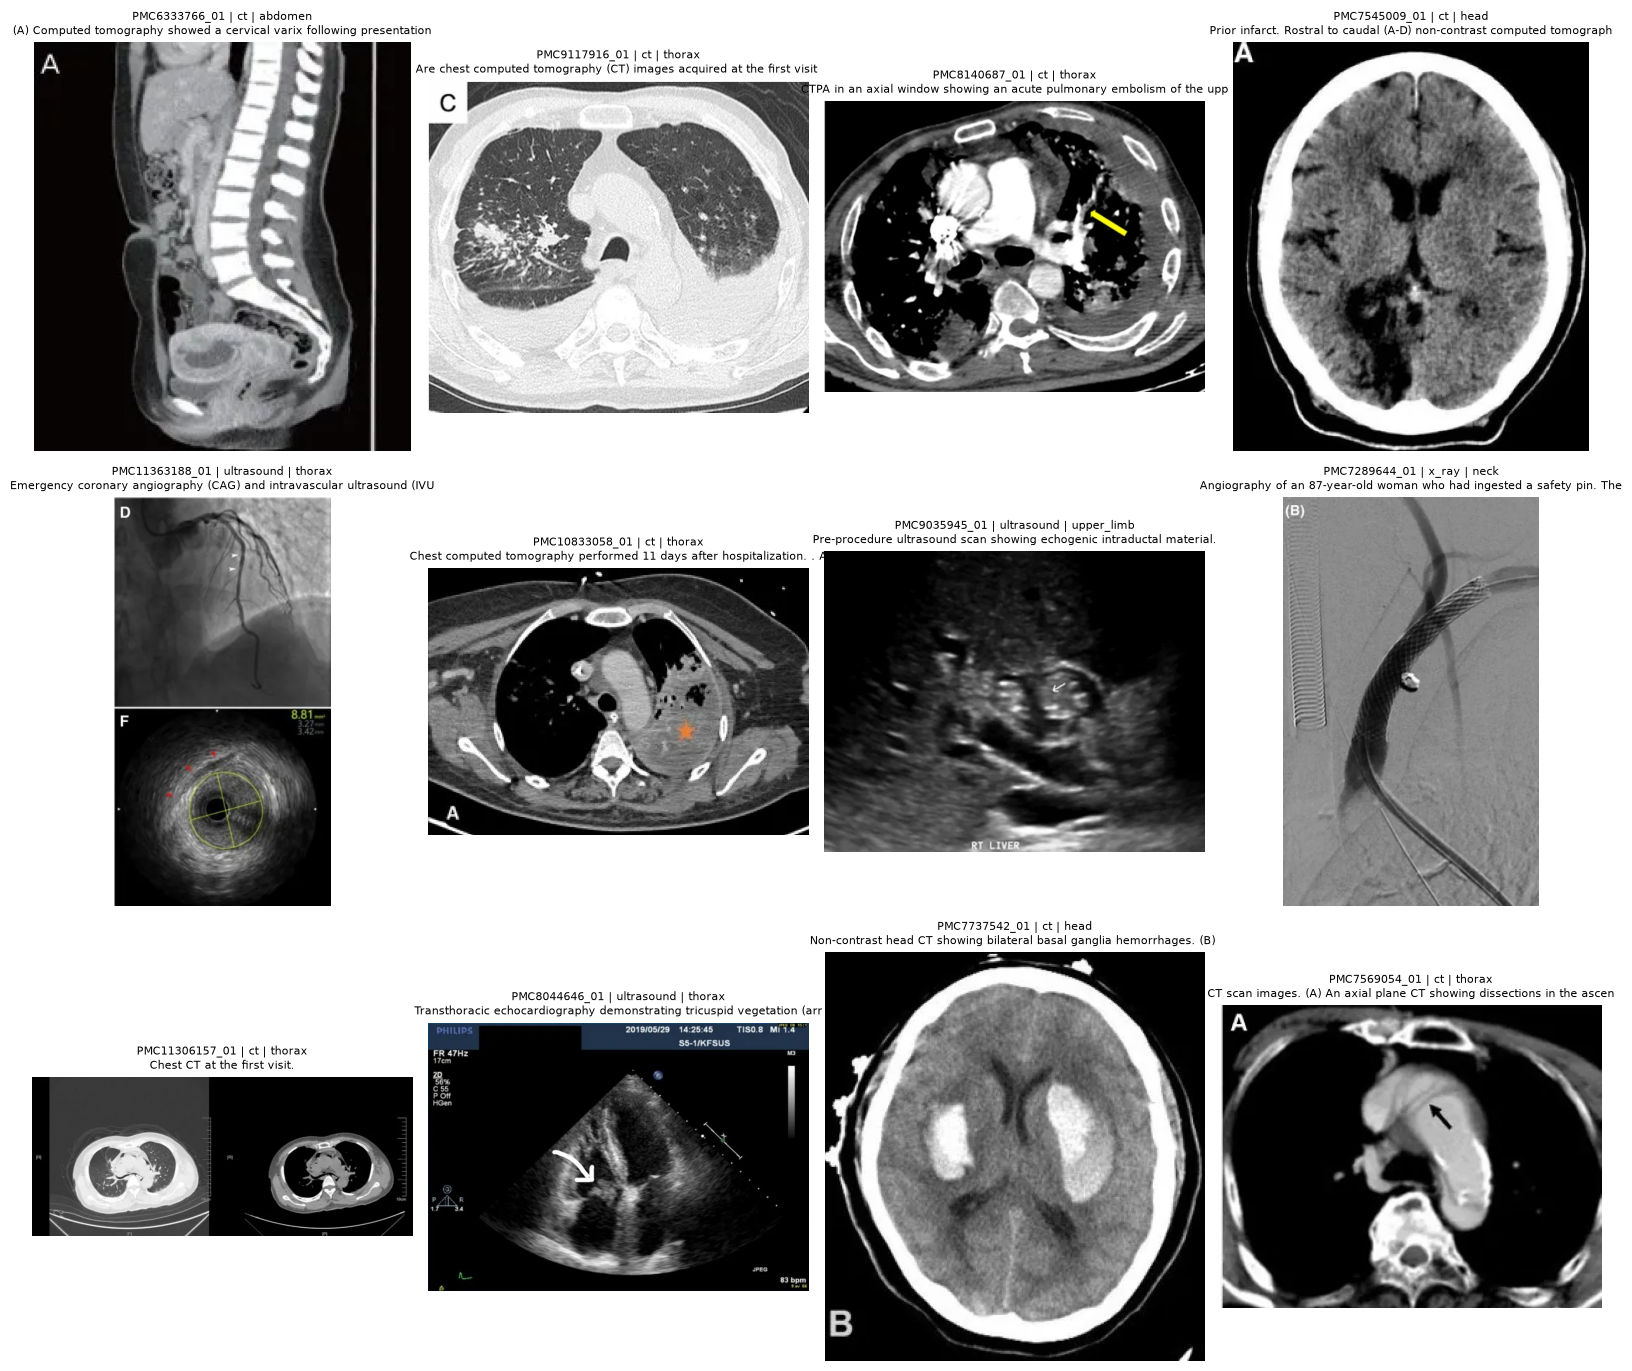

In [12]:
# Fetch image pixels for any row of `images` / `ed` (uses the cached shards)
_shards = {}

def load_image(shard, row):
    if shard not in _shards:
        pf = pq.ParquetFile(IMAGE_FILES[shard])
        sizes = [pf.metadata.row_group(i).num_rows for i in range(pf.num_row_groups)]
        _shards[shard] = (pf, np.cumsum([0, *sizes]))
    pf, starts = _shards[shard]
    rg = int(np.searchsorted(starts, row, side="right") - 1)
    cell = pf.read_row_group(rg, columns=["image"]).column("image")[row - starts[rg]].as_py()
    return Image.open(io.BytesIO(cell["bytes"]))


def show_grid(df, n=12, cols=4, seed=SEED):
    rows = df.sample(min(n, len(df)), random_state=seed)
    fig, axes = plt.subplots(int(np.ceil(len(rows) / cols)), cols, figsize=(4 * cols, 4.6 * np.ceil(len(rows) / cols)))
    for ax, (_, r) in zip(np.ravel(axes), rows.iterrows()):
        ax.imshow(load_image(r["shard"], r["row"]).convert("RGB"))
        ax.set_title(f"{r['patient_id']} | {r['image_subtype']} | {r['radiology_region']}\n"
                     f"{str(r['caption'])[:70]}", fontsize=8)
    for ax in np.ravel(axes):
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_grid(ed)